In [2]:
import sympy as sp
import numpy as np
import scipy
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from sympy import  symbols, sin , cos, lambdify, atan, acos, nsolve
from scipy.optimize import fsolve, least_squares
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

In [ ]:
theta1, theta2, theta3, theta4 = dynamicsymbols('theta1, theta2, theta3, theta4')
d, r, t = symbols('d, r, t')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))
D = N.orientnew('D', 'Axis', (N.z, -theta4))

thetadot1 = 1 #Relación de engranajes 1:1
thetadot2 = 1

t_ = np.linspace(0, 2*np.pi, 50)

theta_1 = list(np.deg2rad(90) + thetadot1*t_)
theta_4 = list(np.deg2rad(90) - thetadot2*t_)
cost = []

def trayectoria(OA, AB, BC, CD, AS, AD): 
    pos = OA*A.x + AB*B.x + BC*C.x + CD*D.x - AD*N.x
    vel = pos.diff(t, N).simplify()
    ace = vel.diff(t, N).simplify()
    pos_fun = lambdify([theta1, theta2, theta3, theta4], [pos.dot(N.x), pos.dot(N.y)])

    z0 = [np.deg2rad(50), np.deg2rad(90)] 
    theta_2, theta_3 = [], []

    for i in range(len(t_)):
        fsolve_fun = lambda z: pos_fun(theta_1[i], z[0], z[1], theta_4[i])
        out = least_squares(fsolve_fun, z0)

        if out.cost > 1*10**(-20):
            print('hola laura')
            return 'xd'
        
        sln = [theta_1[i], out.x[0], out.x[1], theta_4[i]]
        z0 = [sln[1], sln[2]]
        theta_2.append(sln[1])
        theta_3.append(sln[2])
    
    eq2 = OA*A.x + AS*B.x
    pos2 = lambdify([theta1, theta2], [eq2.dot(N.x), eq2.dot(N.y)])
    x_pos, y_pos = [], []
    print('cebolla')

    for i in range(len(t_)):
        x, y = pos2(theta_1[i], theta_2[i])
        x_pos.append(x)
        y_pos.append(y)
        
    return [x_pos, y_pos]

In [57]:
p_list = np.array([[0.3, 0.2], [0.34459, 0.19626], [0.29793, 0.22130],\
                       [0.25897, 0.2], [0.3, 0.2]]) 
x_l = p_list[:, 0]
y_l = p_list[:, 1]

spline_x = CubicSpline(range(len(x_l)), x_l, bc_type='periodic')
spline_y = CubicSpline(range(len(y_l)), y_l, bc_type='periodic')

t_l = np.linspace(0, len(x_l) - 1, 100)
x_p = spline_x(t_l)
y_p = spline_y(t_l)

spline_x

### Mi super función de optimización casera

In [ ]:
def opt_params(spl_star, x): #X es mi lista de parametros de mi guess inicial 
    params, error = CompararSpls(spl_star, x) 
    cambio_iter, op_val, n = [], 0.01, 1 #lista de error en cada iter, valor que voy a ir sumando o restando a los parametros

    for j in range(5): #Por ahora solo pongo la cantidad de iteraciones que quiero hacer 
        list_er, list_p = [], [params[0], params[1], params[2], params[3], params[4], params[5]]

        for i in range(len(list_p)): #quiero hallar la operacion que me de el error más pequeño
            list_p[i] = list_p[i] + op_val
            _, er_val = CompararSpls(spl_star, list_p)

            if er_val > error:
                list_p[i] = list_p[i] - op_val*2
                _, er_val = CompararSpls(spl_star, list_p)

                if er_val > error: list_p[i] = params[i]; list_er.append([0.0, er_val])
                else: list_er.append([-op_val, er_val])

            else: list_er.append([op_val, er_val])
            list_p = [params[0], params[1], params[2], params[3], params[4], params[5]] 
            #reescribo para probar cada parametro antes de hacer la iteración completa
        
        er_select, val = np.array(list_er)[:,1], np.array(list_er)[:,0]
        # print(val)

        if all([x == 0 for x in val]):
            op_val = op_val*0.1**n
            n = n + 1
        
        else:
            error = min(er_select)
            cambio_iter.append(error)
            index = np.where(er_select == min(er_select))[0][0]
            params[index] = params[index] + val[index]
    
    return error, cambio_iter, params

In [55]:
max(cost)

4.138302358821719e-20

In [15]:
OA = 0.03/2
AB = 0.2*1/2
BC = 0.2/2
CD = 0.03*3/2
AS = (0.2*2 + 0.1)/2
AD = 0.25/2

pos = OA*A.x + AB*B.x + BC*C.x + CD*D.x - AD*N.x

pos_fun = lambdify([theta1, theta2, theta3, theta4], [pos.dot(N.x), pos.dot(N.y)])
z0 = [np.deg2rad(50), np.deg2rad(90)] 
theta_2, theta_3 = [], []

fsolve_fun = lambda z: pos_fun(theta_1[1], z[0], z[1], theta_4[1])
out = least_squares(fsolve_fun, z0)    
sln = [theta_1[1], out.x[0], out.x[1], theta_4[1]]

type(out.success)

bool

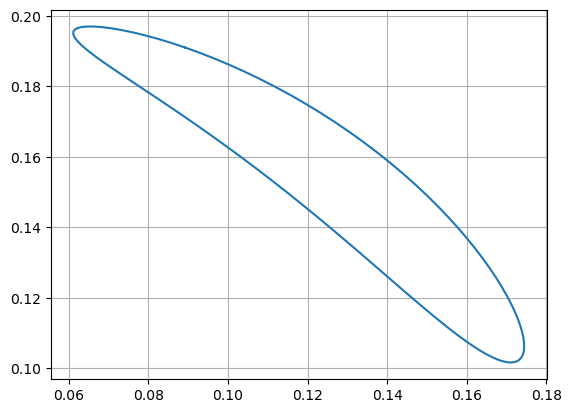

In [35]:
OA = 0.03/2.5
AB = 0.2*1/2.5
BC = 0.2/2.5
CD = 0.03*3/2.5
AS = (0.2*2 + 0.1)/2.5
AD = 0.25/2.5

a = trayectoria(OA, AB, BC, CD, AS, AD) #Dimensiones que quiero optimizar 
plt.plot(a[0], a[1])
plt.grid(True)

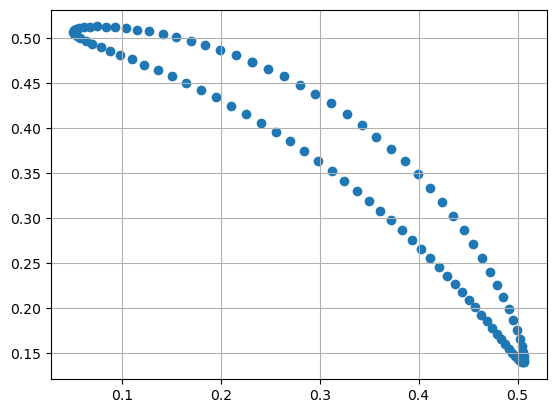

In [4]:
OA = 0.03
AB = 0.2*0.6
BC = 0.2
CD = 0.03*3
AS = 0.2*2 + 0.1
AD = 0.25

a = trayectoria(OA, AB, BC, CD, AS, AD)
plt.scatter(a[0], a[1])
plt.grid(True)


In [2]:
import sys
import time
import threading
from itertools import count
from handythread import foreach

In [3]:
def f(x):
    print(x)
    time.sleep(0.5)
foreach(f, range(10))

def g(x):
    time.sleep(0.5)
    print(x)    
    time.sleep(0.5)
foreach(g, range(10))

0
1
2
3
4
5
6
7
8
9
0
1
2
54

3
6
7
8
9


In [ ]:
C0, C1, C2, C3, C4, C5 = symbols('C0, C1, C2, C3, C4, C5')
theta, beta = symbols('theta, beta')

eq3 = C3 + C4 + C5 - 1
eq1 = (3/90)*C3 + (4/90)*C4 + (5/90)*C5
eq2 = (1/(90**2))*(6*C3 + 12*C4 + 20*C5)

sp.solve([eq3, eq1, eq2], [C3, C4, C5])

{C3: 10.0000000000000, C4: -15.0000000000000, C5: 6.00000000000000}

In [ ]:
x_list, y_list = list(spl1[0][0]), list(spl1[0][1])
min_x = x_list.index(min(x_list))
x_list1 = x_list[min_x: len(x_list)-1] + x_list[0: min_x] + [x_list[min_x]]

max_y = np.where(y_list == y_list.max())[0][0] 

y_list1 = np.concatenate((y_list[max_y: len(y_list)-1], y_list[0: max_y], np.array([y_list[max_y]])))

a = x_list[min_x: len(x_list)-1]+ x_list[0: min_x] + [x_list[min_x]]


np.array(x_list[min_x: len(x_list)-1] + x_list[0: min_x] + [x_list[min_x]])

In [ ]:
np.array(['hola', 'xd']).T #La transpuesta xd

array(['hola', 'xd'], dtype='<U4')

## Plotear splines del csv

In [58]:
file_path = 'splines.csv'
data = pd.read_csv(file_path, delimiter=',') 
data = data.drop(['CODIGO'], axis = 1)
num = 100 #Numero de puntos tanto para el spline como para la trayectoria (cinematica)

for i in data:
    data[i] = data[i].multiply(1/1000)

data.head()

,X1,Y1,X2,Y2,X3,Y3,X4,Y4
0,0.3,0.20000,0.34459,0.19626,0.29793,0.22130,0.25897,0.20000
1,0.3,0.18660,0.33710,0.22790,0.29793,0.22130,0.25897,0.20000
2,0.3,0.16944,0.35140,0.21909,0.31767,0.20663,0.26194,0.18528
3,0.3,0.18983,0.35380,0.21210,0.30000,0.20295,0.26194,0.18528
4,0.3,0.21998,0.35448,0.20094,0.29910,0.23578,0.27954,0.21652


In [59]:
def plotSpline(n):
    p_list = np.array([[data['X1'][n], data['Y1'][n]], [data['X2'][n], data['Y2'][n]], [data['X3'][n], data['Y3'][n]],\
                       [data['X4'][n], data['Y4'][n]], [data['X1'][n], data['Y1'][n]]]) 
    x_l = p_list[:, 0] #los 4 puntos que determinan el spline
    y_l = p_list[:, 1]

    spline_x = CubicSpline(range(len(x_l)), x_l, bc_type='periodic')
    spline_y = CubicSpline(range(len(y_l)), y_l, bc_type='periodic')

    t_l = np.linspace(0, len(x_l) - 1, num)
    x_p = spline_x(t_l) #Lista de puntos de los splines
    y_p = spline_y(t_l)

    spl_l = [[x_p, y_p], [x_l, y_l]]
    
    return np.column_stack((spl_l[0][0], spl_l[0][1]))

In [60]:
plots = []
for i in range(len(data)):
    lista = [plotSpline(i)[:,0], plotSpline(i)[:,1]]
    plots.append(lista)

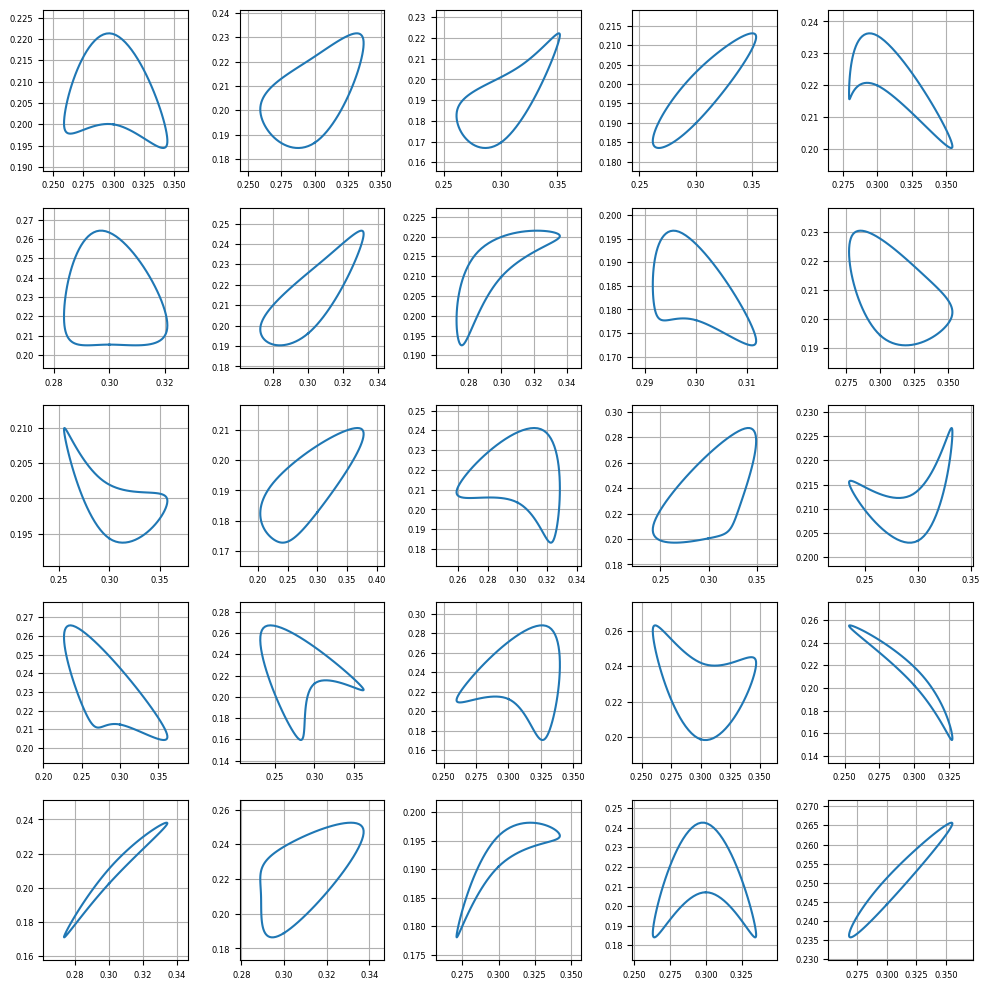

In [61]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for ax, (x, y) in zip(axes.flat, plots):
    ax.plot(x, y)
    ax.axis('on') 
    x_pad = (x.max() - x.min()) * 0.2
    y_pad = (y.max() - y.min()) * 0.2
    ax.set_xlim(x.min() - x_pad, x.max() + x_pad)
    ax.set_ylim(y.min() - y_pad, y.max() + y_pad)
    ax.grid(True)
    ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

In [ ]:
def opt_params(spl_star, x): #X es mi lista de parametros de mi guess inicial 
    params, error = CompararSpls(spl_star, x) 
    cambio_iter, op_val, n = [], 0.01, 1 #lista de error en cada iter, valor que voy a ir sumando o restando a los parametros

    for j in range(5): #Por ahora solo pongo la cantidad de iteraciones que quiero hacer 
        list_er, list_p = [], [params[0], params[1], params[2], params[3], params[4], params[5]]

        for i in range(len(list_p)): #quiero hallar la operacion que me de el error más pequeño
            list_p[i] = list_p[i] + op_val
            _, er_val = CompararSpls(spl_star, list_p)

            if er_val > error:
                list_p[i] = list_p[i] - op_val*2
                _, er_val = CompararSpls(spl_star, list_p)

                if er_val > error: list_p[i] = params[i]; list_er.append([0.0, er_val])
                else: list_er.append([-op_val, er_val])

            else: list_er.append([op_val, er_val])
            list_p = [params[0], params[1], params[2], params[3], params[4], params[5]] 
            #reescribo para probar cada parametro antes de hacer la iteración completa
        
        er_select, val = np.array(list_er)[:,1], np.array(list_er)[:,0]
        # print(val)

        if all([x == 0 for x in val]):
            op_val = op_val*0.1**n
            n = n + 1
        
        else:
            error = min(er_select)
            cambio_iter.append(error)
            index = np.where(er_select == min(er_select))[0][0]
            params[index] = params[index] + val[index]
    
    return error, cambio_iter, params

     message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [ 1.538e-01]
           x: [ 2.205e+00  3.586e-02  2.676e+00  8.744e-01]
        cost: 0.011833003258226707
         jac: [[-1.118e-01 -1.336e-02  1.599e-01  1.228e-01]]
        grad: [-1.720e-02 -2.056e-03  2.459e-02  1.888e-02]
  optimality: 0.06336124917440185
 active_mask: [0 0 0 0]
        nfev: 52
        njev: 33

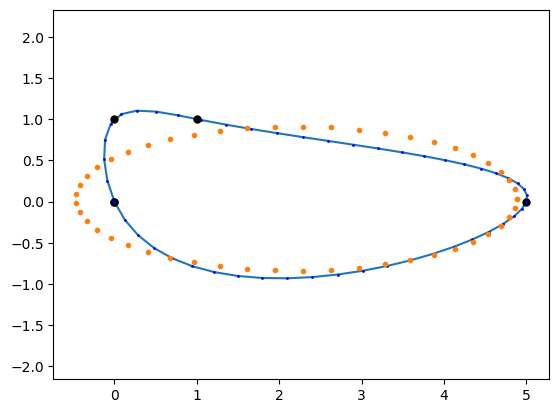

In [ ]:
import scipy
import numpy as np
import matplotlib.pyplot as plt
 
class ClosedSpline:
    def __init__(self, points, n=100): #self se reemplaza con el nombre de la variable 
        self.points = np.array(points)
        self.tt = np.linspace(0, 1, n)
        t = np.linspace(0, 1, len(self.points))
        self.interp,u = scipy.interpolate.splprep([self.points[:,0],self.points[:,1]],s=0,per=True)
        self.xx,self.yy = scipy.interpolate.splev(self.tt,self.interp)
       
    def plot(self,ax=None):

        if ax is None:
            ax = plt.gca()
        ax.plot(self.xx, self.yy)
        ax.plot(self.points[:,0], self.points[:,1], 'k.', markersize=10)
        ax.plot(self.xx, self.yy, 'b.', markersize=2)
        ax.axis('equal')
 
# Create a circle with center and radius
def circle(center, radius, n=100):
    tt = np.linspace(0, 2*np.pi, n)
    xx = center[0] + radius*np.cos(tt)
    yy = center[1] + radius*np.sin(tt)
    return xx, yy
 
def elipse(center, a, b, n=100):
    tt = np.linspace(0, 2*np.pi, n)
    xx = center[0] + a*np.cos(tt)
    yy = center[1] + b*np.sin(tt)
    return xx, yy
 
def CurveLength(xx,yy):  
    return np.sum(np.sqrt(np.diff(xx)**2+np.diff(yy)**2))
 
def CompareCurves(xx, yy, xx_star,yy_star):
    kdt = scipy.spatial.KDTree(np.array([xx_star, yy_star]).T)
    er = 0

    for i,xi in enumerate(xx):
        distance, idx = kdt.query([xi, yy[i]])
        er = er + distance #Suma del error 

    l = CurveLength(xx,yy)
    l_star = CurveLength(xx_star, yy_star)
    return er/len(xx) + 0.05*np.abs(l-l_star)

# Example usage
points = [[0,0], [5,0], [1,1], [0,1],[0,0]]
spline = ClosedSpline(points, n = 50)
#circle_x,circle_y=circle([1,0], 1,50)
#spline.plot()
#plt.plot(circle_x,circle_y,'.')
 
def opt_fun(x):
    #circle_x,circle_y = circle([x[0],x[1]], x[2],50)
    circle_x,circle_y = elipse([x[0],x[1]], x[2],x[3],50)
    return CompareCurves(spline.xx,spline.yy, circle_x,circle_y)
 
opt_out = scipy.optimize.least_squares(opt_fun,[0,0,3,1],bounds=([-1,-1,0.1,0.1],[4,4,5,5]))
#opt_out=scipy.optimize.least_squares(opt_fun,[0,0,1],bounds=([-1,-1,0.1],[4,4,5]))
circle_x,circle_y = circle([opt_out.x[0],opt_out.x[1]], opt_out.x[2],50)

circle_x,circle_y = elipse([opt_out.x[0],opt_out.x[1]], opt_out.x[2],opt_out.x[3],50)
 
spline.plot()
plt.plot(circle_x,circle_y,'.')
opt_out

In [ ]:
import numpy as np
from scipy.spatial import KDTree
x, y = np.mgrid[0:5, 2:8]
tree = KDTree(np.c_[x.ravel(), y.ravel()])

a = [[0, 0], [2.2, 2.9], [4.1, 4.1]]
er = 0

for i, xi in enumerate(a):
    dd, ii = tree.query([xi[0], xi[1]])
    er = er + dd
    # print(dd, ii, sep='\n')

er

2.3650281539872884

In [30]:
dd, ii = tree.query([[0, 0], [2.2, 2.9], [4.1, 4.1]], k=1)
print(dd, ii, sep='\n')

sum(dd)

[2.         0.2236068  0.14142136]
[ 0 13 26]


2.3650281539872884

In [8]:
Kc, Kp, ti, tp, s = symbols('K_c, K_p, tau_i, tau_p, s')

eq = (Kc*(1 + (1/(ti*s)))*(Kp/(tp*s + 1))) / (1+ (Kc*(1 + (1/(ti*s)))*(Kp/(tp*s + 1))))

eq.simplify()

K_c*K_p*(s*tau_i + 1)/(K_c*K_p*(s*tau_i + 1) + s*tau_i*(s*tau_p + 1))

In [ ]:
def denormalization():
    centro = spl.mean(axis=0)
    spl = spl - centro
    svd = np.linalg.svd(spl)
    spl = np.matmul(svd.Vh, spl.T).T / np.max(svd.S)
    return spl, centro, svd.Vh, svd.S

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from scipy.optimize import least_squares
import matplotlib.animation as animation
from IPython.display import HTML

# =============================================================================
# 1. Definición simbólica del mecanismo y sus vectores de posición
# =============================================================================

# Definimos los ángulos dinámicos y las longitudes de los eslabones
theta1, theta2, theta3, theta4 = dynamicsymbols('theta1, theta2, theta3, theta4')
t = sp.symbols('t')
l_OA, l_AB, l_BC, l_CD, l_AS, l_AD = sp.symbols('OA, AB, BC, CD, AS, AD')

# Sistema de referencia y marcos asociados a cada eslabón
N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))
D = N.orientnew('D', 'Axis', (N.z, -theta4))

# Asumimos las relaciones de engranaje para imponer θ₁ y θ₄
thetadot1 = 1  # relación 1:1 por ejemplo
thetadot2 = 1

# Definimos el vector de tiempo y las trayectorias impuestas para θ₁ y θ₄
num = 100  # número de frames
t_ = np.linspace(0, 2*np.pi, num)
theta_1_array = list(np.deg2rad(90) + thetadot1 * t_)
theta_4_array = list(np.deg2rad(90) - thetadot2 * t_)

# Definimos la posición final del mecanismo usando la combinación de vectores
# Nota: se suma l_OA*A.x, l_AB*B.x, l_BC*C.x, l_CD*D.x y se resta l_AD*N.x
posicion = l_OA * A.x + l_AB * B.x + l_BC * C.x + l_CD * D.x - l_AD * N.x
# La función se evalúa en las componentes x e y del sistema N
posicion_fun = sp.lambdify(
    [l_OA, l_AB, l_BC, l_CD, l_AD, theta1, theta2, theta3, theta4],
    [posicion.dot(N.x), posicion.dot(N.y)],
    "numpy"
)

# Otra función para la posición intermedia (por ejemplo, la articulación S)
eq2 = l_OA * A.x + l_AS * B.x
pos2_fun = sp.lambdify(
    [l_OA, l_AS, theta1, theta2],
    [eq2.dot(N.x), eq2.dot(N.y)],
    "numpy"
)

# =============================================================================
# 2. Resolución de la cinemática interna y cálculo de la trayectoria
# =============================================================================

def trayectoria(OA, AB, BC, CD, AS, AD):
    """
    Para cada frame (definido por t_), resuelve θ₂ y θ₃
    para que la función de posición coincida con la cinemática,
    y calcula la trayectoria de una articulación intermedia.
    """
    # Estimación inicial para θ₂ y θ₃
    z0 = [np.deg2rad(50), np.deg2rad(90)]
    theta_2_array, theta_3_array = [], []
    
    # Se recorre cada instante del vector de tiempo
    for i in range(len(t_)):
        # Se define la función residual a minimizar
        fsolve_fun = lambda z: np.array(
            posicion_fun(OA, AB, BC, CD, AD,
                         theta_1_array[i],
                         z[0],
                         z[1],
                         theta_4_array[i]),
            dtype=float
        )
        out = least_squares(fsolve_fun, z0)
        sln = [theta_1_array[i], out.x[0], out.x[1], theta_4_array[i]]
        z0 = [sln[1], sln[2]]  # Actualizamos la suposición inicial para el siguiente step
        theta_2_array.append(sln[1])
        theta_3_array.append(sln[2])
        
        if out.cost > 1e-6:
            print("Advertencia: coste elevado en la iteración", i)
            return None, None
    
    # Con las soluciones calculadas, evaluamos la trayectoria de la articulación definida por pos2
    x_pos, y_pos = [], []
    for i in range(len(t_)):
        x, y = pos2_fun(OA, AS, theta_1_array[i], theta_2_array[i])
        x_pos.append(x)
        y_pos.append(y)
    
    # Retornamos la trayectoria y los ángulos para cada frame
    return (x_pos, y_pos), (theta_1_array, theta_2_array, theta_3_array, theta_4_array)

# =============================================================================
# 3. Definición de parámetros numéricos y cálculo previo de la trayectoria
# =============================================================================

# Valores numéricos asignados a las longitudes del mecanismo (ajústalos según tu caso)

params_values = { l_OA: 0.00601663, l_AB: 0.03222794, l_BC: 0.0313002, l_CD: 0.01801227, l_AS: 0.13830748, l_AD: 0.05027739}
OA_val = params_values[l_OA]
AB_val = params_values[l_AB]
BC_val = params_values[l_BC]
CD_val = params_values[l_CD]
AS_val = params_values[l_AS]
AD_val = params_values[l_AD]

# Se llama a la función trayectoria para obtener los ángulos calculados y la posición de la articulación intermedia
traj, angles = trayectoria(OA_val, AB_val, BC_val, CD_val, AS_val, AD_val)

fig, ax = plt.subplots(figsize=(9, 5))
path_S_x, path_S_y = [], []
def update(frame):
    ax.cla()
    ax.set_xlim(-0.05, 0.2)
    ax.set_ylim(-0.05, 0.15)
    ax.set_xlabel("Posición en X (m)")
    ax.set_ylabel("Posición en Y (m)")
    ax.set_title("Mecanismo animado")
    ax.grid(True)
    ax.set_aspect('equal', adjustable='box')
    
    th1 = angles[0][frame]
    th2 = angles[1][frame]
    th3 = angles[2][frame]
    th4 = angles[3][frame]

    O = np.array([0, 0])
    A_pos = np.array([OA_val * np.cos(th1), OA_val * np.sin(th1)])
    B_pos = A_pos + np.array([AB_val * np.cos(th1 - th2), AB_val * np.sin(th1 - th2)])
    C_pos = B_pos + np.array([BC_val * np.cos(th1 - th2 - th3), BC_val * np.sin(th1 - th2 - th3)])
    D_pos = np.array([AD_val, 0])
    
    pt2 = np.array(pos2_fun(OA_val, AS_val, th1, th2))
    path_S_x.append(pt2[0])
    path_S_y.append(pt2[1])
    
    ax.plot([O[0], A_pos[0]], [O[1], A_pos[1]])
    ax.plot([A_pos[0], B_pos[0]], [A_pos[1], B_pos[1]])
    ax.plot([B_pos[0], C_pos[0]], [B_pos[1], C_pos[1]])
    ax.plot([C_pos[0], D_pos[0]], [C_pos[1], D_pos[1]])
    ax.plot([A_pos[0], pt2[0]], [A_pos[1], pt2[1]])
    ax.plot(path_S_x, path_S_y, 'k--')
    
ani = animation.FuncAnimation(fig, update, frames=len(t_), interval=50)

plt.close(fig)
HTML(ani.to_jshtml())

In [ ]:
spl_guess = np.array(trayectoria(*opt_params)[0]).T
x_c1, y_c1 = centroid(spl_guess[:,0], spl_guess[:,1])

spl_19 = plotSpline(19)
x_c, y_c = centroid(spl_19[:, 0], spl_19[:, 1]) 

trasl = np.array([x_c1 - x_c, y_c1 - y_c])
spl_19 = np.array((spl_19[:,0] + trasl[0],  spl_19[:,1] + trasl[1])).T

plt.plot(spl_guess[:,0], spl_guess[:,1])

plt.plot(x_c1, y_c1, 'bo')
plt.grid(True)

In [33]:
import sympy as sp
import numpy as np
import pandas as pd
import scipy
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from sympy import  symbols, sin , cos, lambdify, atan, acos, nsolve
from scipy.optimize import fsolve, least_squares, differential_evolution
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

In [56]:
theta1, theta2, theta3, theta4, theta5 = dynamicsymbols('theta1, theta2, theta3, theta4, theta5')
t = symbols('t')
l_OA, l_AB, l_BC, l_CD, l_AS, l_AD = symbols('OA, AB, BC, CD, AS, AD')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = N.orientnew('B', 'Axis', (N.z, theta2))
C = N.orientnew('C', 'Axis', (N.z, theta3))
D = N.orientnew('D', 'Axis', (N.z, -theta4))
E = N.orientnew('D', 'Axis', (N.z, theta5))

thetadot1 = 1 #Relación de engranajes 1:1
thetadot2 = 1

t_ = np.linspace(0, 2*np.pi, num)
theta_1 = list(np.deg2rad(90) + thetadot1*t_)
theta_4 = list(np.deg2rad(90) - thetadot2*t_)

posicion = l_OA*A.x + l_AB*B.x + l_BC*C.x + l_CD*D.x - l_AD*N.x
posicion_fun = lambdify([l_OA, l_AB, l_BC, l_CD, l_AD, theta1, theta2, theta3, theta4], [posicion.dot(N.x), posicion.dot(N.y)])

eq2 = l_OA*A.x + l_AS*E.x
pos2 = lambdify([l_OA, l_AS, theta1, theta5], [eq2.dot(N.x), eq2.dot(N.y)])

def trayectoria(OA, AB, BC, CD, AS, AD): 
    z0 = [np.deg2rad(40), np.deg2rad(160)] 
    theta_2, theta_3 = [], []

    for i in range(len(t_)):
        fsolve_fun = lambda z: posicion_fun(OA, AB, BC, CD, AD, theta_1[i], z[0], z[1], theta_4[i])
        out = least_squares(fsolve_fun, z0)
        sln = [theta_1[i], out.x[0], out.x[1], theta_4[i]]
        z0 = [sln[1], sln[2]]
        theta_2.append(sln[1]); theta_3.append(sln[2])
        
        # if out.cost > 1*10**(-6):
        #     return np.array([[None, None], [None, None]]).T

    x_pos, y_pos = [], []
    for i in range(len(t_)):
        x, y = pos2(OA, AS, theta_1[i], theta_2[i])
        x_pos.append(x); y_pos.append(y)
    
    return [[x_pos, y_pos], [OA, AB, BC, CD, AS, AD], (theta_1, theta_2, theta_3, theta_4)] 

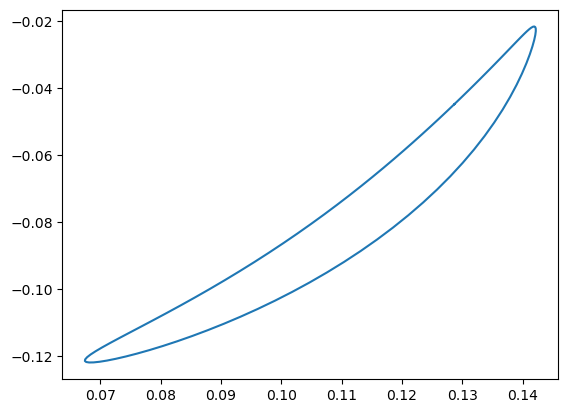

In [57]:
opt_params = [0.00601663, 0.03222794, 0.0313002, 0.01801227, 0.13830748, 0.05027739]
a = np.array(trayectoria(*opt_params)[0]).T

plt.plot(a[:,0], a[:,1])


In [ ]:
t_ = np.linspace(0, 1, 100)

theta_1 =  12.431*t_**5 + -31.07*t_**4 + 20.718*t_**3 + 0*t_**2 + 0*t_ + 0.1424
theta_4 =  9.32*t_**5 + -23.300*t_**4 + 15.533*t_**3 + 0*t_**2 + 0*t_ + 1.588

plt.plot(t_, theta_4)
plt.plot(t_, theta_1)

In [1]:
import pandas as pd 
import numpy as np

# A structured array
my_array = np.ones(3, dtype=([('foo', int), ('bar', float)]))
# Print the structured array
print(my_array['foo'])

# A record array
my_array2 = my_array.view(np.recarray)
# Print the record array
print(my_array2.foo)

[1 1 1]
[1 1 1]


In [2]:
my_2darray = np.array([[1, 2, 3], [4, 5, 6]])
print(pd.DataFrame(my_2darray))

   0  1  2
0  1  2  3
1  4  5  6
